This notebook assumes that scVI and SOLO have already been run and doublet predictions are available.

Here, a dummy high resolution Leiden clustering is run atop to pick up to detect doublet clusters.

Assuming that doublet cells are clustering together, the removal of clusters with a certain percentage of cells predicted to be doublets may help remove low quality cells.

In [ ]:
# No need to restart notebook when editing custom packages
%load_ext autoreload
%autoreload 2

In [5]:
from pathlib import Path
import tempfile
import os 

import scanpy as sc
import scvi
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import dotenv_values

# Suppress warnings
import warnings
warnings.filterwarnings("ignore")

In [ ]:
# Import config and construct/define variables
CONFIG = dotenv_values("config.env") # assuming kernel located at the root of the directory
DATA_ROOT_DIR = Path(CONFIG['DATADIR'])
MODELDIR = DATA_ROOT_DIR / "3_solo" / "all_solo" 
PLOTS_DIR = MODELDIR / 'plots'
DOUBLET_OUTPUT_DIR = MODELDIR / 'metrics'
CELL_HISTORY = DATA_ROOT_DIR / "qc_log.csv" #QC log

CLUSTER_PCT_DOUBLET_CUTOFF = 0.25 # percentage of cells flagged as doublet for a cluster to be flagged as a doublet cluster

### Let's load the AnnData

In [9]:
adata = sc.read_h5ad(Path(MODELDIR, 'datasets', 'raw.h5ad'))
embed_only = sc.read_h5ad(Path(MODELDIR, 'datasets', 'embed_only.h5ad'), backed='r')

In [10]:
adata.obsm = embed_only[adata.obs_names].obsm
adata.uns = {k: v for k, v in embed_only.uns.items() if k in {'tsne', 'umap', 'neighbors'}}
adata.obsp = embed_only.obsp

del embed_only
adata

AnnData object with n_obs × n_vars = 2030770 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'cluster_id_label', 'supertype_id_label', 'subclass_id_label', 'class_id_label', 'C66_named', 'C185_named', 'C286_named', 'C465_named'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene'
    uns: 'neighbors', 'tsne', 'umap'
    obsm: 'X_embed', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'

### load predictions and add to anndata

In [11]:
control_preds = pd.read_csv(DOUBLET_OUTPUT_DIR / f'solo_doublets_control.csv', index_col=0)
non_control_preds = pd.read_csv(DOUBLET_OUTPUT_DIR / f'solo_doublets_non_control.csv', index_col=0)

In [12]:
control_preds.IsDoublet.mean(), non_control_preds.IsDoublet.mean()

(np.float64(0.09489171962499754), np.float64(0.12286545442777709))

In [13]:
adata.obs["IsDoublet"] = False
adata.obs.loc[non_control_preds.index, "IsDoublet"] = non_control_preds.values
adata.obs.loc[control_preds.index, "IsDoublet"] = control_preds.values

# analysis

### Plotting the doublets

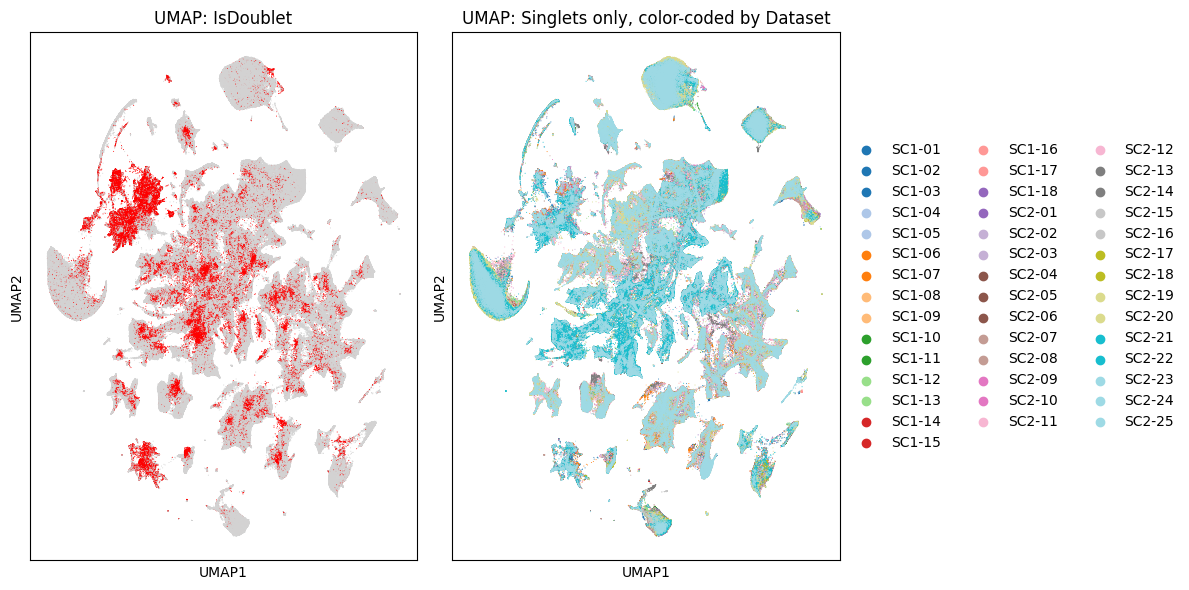

In [15]:
doublet_palette = {
    'True': 'red',
    'False': 'lightgrey'
}

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Plot UMAP with 'IsDoublet' on the first subplot
sc.pl.umap(
    adata,
    color='IsDoublet',
    palette=doublet_palette,
    size=2,
    ax=axes[0],
    show=False,  # Prevents immediate display, allowing combined plots
    legend_loc=None
)
axes[0].set_title(f"UMAP: IsDoublet")

# Plot UMAP with 'Dataset' on the second subplot, using a different palette if necessary
sc.pl.umap(
    adata[~adata.obs['IsDoublet']],
    color='Dataset',
    palette='tab20',  # Example alternative palette; adjust as needed
    size=2,
    ax=axes[1],
    show=False,
    #legend_loc=None
)
axes[1].set_title(f"UMAP: Singlets only, color-coded by Dataset")

# Adjust layout and display the final figure
plt.tight_layout()
plt.show()

fig.savefig(PLOTS_DIR / f'doublet_comparison.pdf')

In [16]:
adata.obs['IsDoublet'].value_counts(normalize=True)

IsDoublet
False    0.89319
True     0.10681
Name: proportion, dtype: float64

### Let's identify doublet clusters to catch the stragglers

--> get high res clustering, calculate doublet % per cluster, filter all clusters consisting of more than CLUSTER_PCT_DOUBLET_CUTOFF % doublets

In [17]:
sc.tl.leiden(adata, resolution=100, key_added='doublet_leiden', flavor = "igraph") #190 min

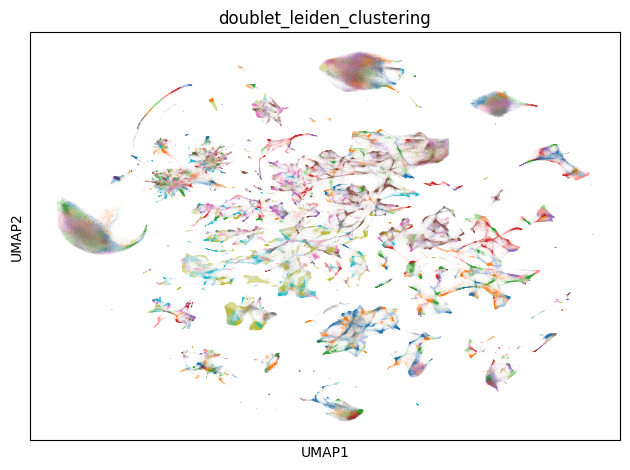

In [18]:
filename = f"doublet_leiden_clustering"

fig, ax = plt.subplots()

sc.pl.umap(adata, color='doublet_leiden', palette='tab20', legend_loc=None, 
show=False, ax=ax)

ax.set_title(filename)

# Adjust layout and display the final figure
plt.tight_layout()
plt.show()

fig.savefig(PLOTS_DIR / f'{filename}.pdf')

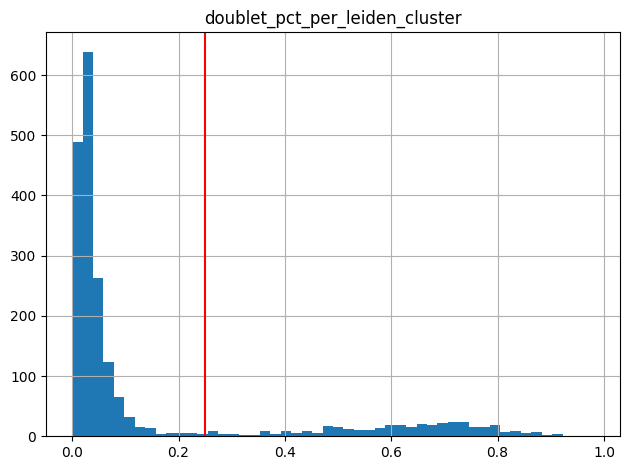

In [19]:
filename = f"doublet_pct_per_leiden_cluster"

cluster_doublet_pct = (adata.obs.groupby('doublet_leiden')['IsDoublet'].sum()/adata.obs['doublet_leiden'].value_counts()).sort_values(ascending=False)
cluster_doublet_pct.hist(bins=50)
plt.axvline(CLUSTER_PCT_DOUBLET_CUTOFF, color='red')
plt.title(filename)
# Adjust layout and display the final figure
plt.tight_layout()
plt.savefig(PLOTS_DIR / f'{filename}.pdf') 
plt.show()


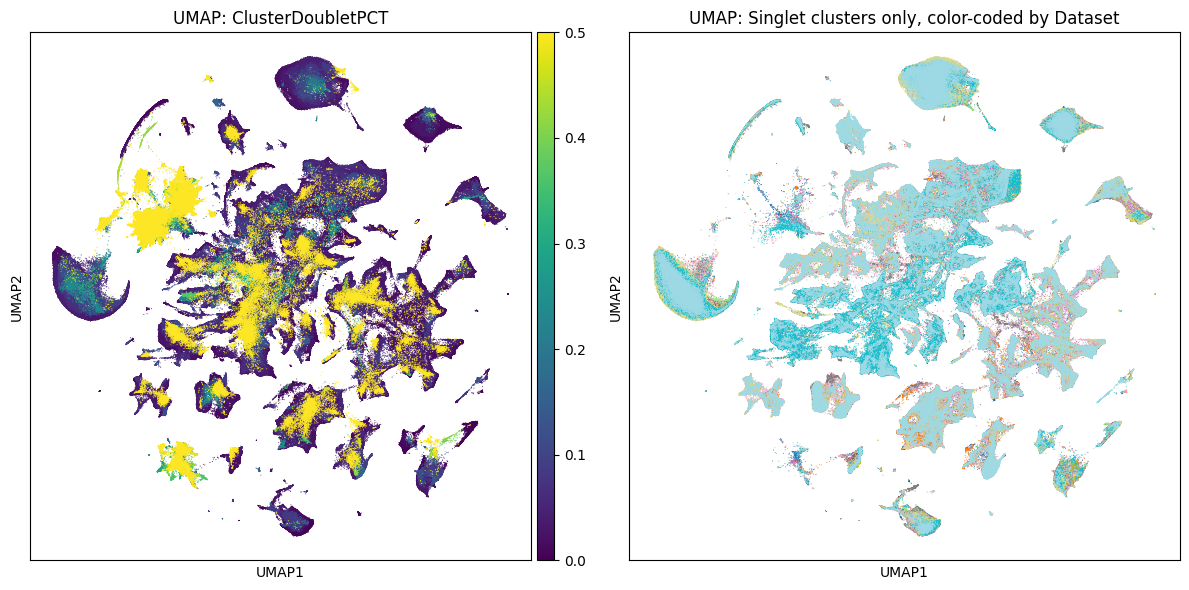

In [20]:
adata.obs['ClusterDoubletPCT'] = adata.obs['doublet_leiden'].map(cluster_doublet_pct)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Plot UMAP with 'IsDoublet' on the first subplot
sc.pl.umap(
    adata,
    color='ClusterDoubletPCT',
    size=2,
    ax=axes[0],
    show=False,  # Prevents immediate display, allowing combined plots
    legend_loc=None,
    vmax=0.5
)
axes[0].set_title(f"UMAP: ClusterDoubletPCT")

# Plot UMAP with 'Dataset' on the second subplot, using a different palette if necessary
sc.pl.umap(
    adata[adata.obs['ClusterDoubletPCT'] < CLUSTER_PCT_DOUBLET_CUTOFF],
    color='Dataset',
    palette='tab20',  # Example alternative palette; adjust as needed
    size=2,
    ax=axes[1],
    show=False,
    legend_loc=None
)
axes[1].set_title(f"UMAP: Singlet clusters only, color-coded by Dataset")

# Adjust layout and display the final figure
plt.tight_layout()
plt.show()

fig.savefig(PLOTS_DIR / f'doublet_comparison_leiden.png')

save the doublets

In [21]:
adata.obs['DoubletToRemove'] = (adata.obs['IsDoublet']) | (adata.obs['ClusterDoubletPCT'] > CLUSTER_PCT_DOUBLET_CUTOFF)

adata.obs['DoubletToRemove'].to_csv(Path(DOUBLET_OUTPUT_DIR, f'all_doublets.csv'))

update QC log

In [24]:
# Load existing file
qc_log_df = pd.read_csv(CELL_HISTORY)

qc_log_df["IsSoloDoublet"] = False 
qc_log_df.loc[qc_log_df["CellID"].isin(adata[adata.obs["IsDoublet"]].obs.index), "IsSoloDoublet"] = True

qc_log_df["IsDoubletCluster"] = False
qc_log_df.loc[qc_log_df["CellID"].isin(adata[(adata.obs['ClusterDoubletPCT'] > CLUSTER_PCT_DOUBLET_CUTOFF)].obs.index), "IsDoubletCluster"] = True

qc_log_df["IsRemovedDoublet"] = False
qc_log_df.loc[qc_log_df["CellID"].isin(adata[adata.obs["DoubletToRemove"]].obs.index), "IsRemovedDoublet"] = True

# Atomically replace cell history to avoid data corruption
output_path = CELL_HISTORY
output_dir = output_path.parent
# Create temp file in same directory
with tempfile.NamedTemporaryFile(mode="w", delete=False, dir=output_dir, suffix=".csv") as tmp:
    temp_path = Path(tmp.name)
    qc_log_df.to_csv(tmp.name, index=False)

os.replace(temp_path, output_path)


In [25]:
qc_log_df.tail()

,CellID,Dataset,Sample,total_counts,n_genes,pct_mito,failed_qc_thresholds,qc_manually_removed,IsSoloDoublet,IsDoubletCluster,IsRemovedDoublet
3129143,SC2-25_SAMN46505609_TTTGTTGGTGTTTGAG,SC2-25,SAMN46505609,5964.0,2798,1.156942,False,False,False,False,False
3129144,SC2-25_SAMN46505609_TTTGTTGGTGTTTGTC,SC2-25,SAMN46505609,8638.0,3488,1.736513,False,False,False,False,False
3129145,SC2-25_SAMN46505609_TTTGTTGGTTGAAGCC,SC2-25,SAMN46505609,384.0,331,1.562500,True,True,False,False,False
3129146,SC2-25_SAMN46505609_TTTGTTGGTTGTTGTC,SC2-25,SAMN46505609,420.0,351,1.666667,True,True,False,False,False
3129147,SC2-25_SAMN46505609_TTTGTTGGTTTACCGT,SC2-25,SAMN46505609,8958.0,3748,0.747935,False,False,True,False,True


### Let's plot %doublets per dataset

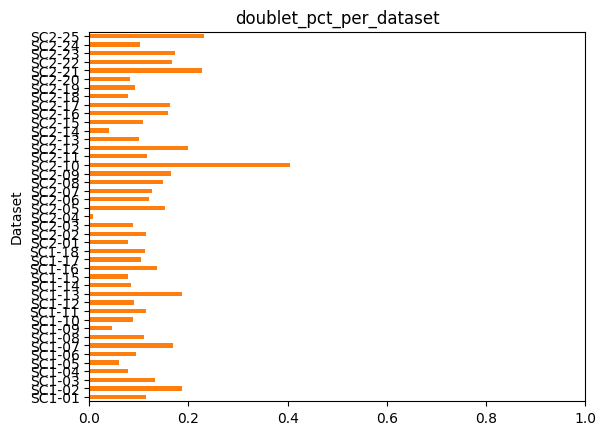

In [26]:
filename = f"doublet_pct_per_dataset"

dataset_pct_doublet = adata.obs.groupby('Dataset')['DoubletToRemove'].sum() / adata.obs['Dataset'].value_counts()
dataset_pct_doublet.plot.barh(color='tab:orange')
plt.xlim(0,1)
plt.grid(False)
plt.title(filename)
plt.savefig(PLOTS_DIR / f'{filename}.pdf') 
plt.show()


### Let's export the new dataset

In [29]:
singlet_only = adata[~adata.obs['DoubletToRemove']]

In [30]:
singlet_only.uns = {k: v for k, v in singlet_only.uns.items() if k in {'tsne', 'umap', 'neighbors'}}
singlet_only.obs.drop(columns=['IsDoublet', 'doublet_leiden', 'DoubletToRemove', "ClusterDoubletPCT"], inplace=True)
singlet_only

AnnData object with n_obs × n_vars = 1725062 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'cluster_id_label', 'supertype_id_label', 'subclass_id_label', 'class_id_label', 'C66_named', 'C185_named', 'C286_named', 'C465_named'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene'
    uns: 'neighbors', 'tsne', 'umap'
    obsm: 'X_embed', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'

In [31]:
singlet_only.write_h5ad(Path(MODELDIR, 'datasets', f'singlets_only.h5ad'))